# Exercice 2

- Reproduire le nuage de point du graphe présenté dans « Régression logistique – A quoi cela ressemble ? » sur base des données de la p.156 (voir le fichier disease.txt sur le portail)

- Utiliser la librairie sklearn pour optimiser un modèle logistique

- Comparer avec les valeurs du modèle annoncées en p.159

- Ajouter la courbe optimale au nuage de point

In [330]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
import math

On charge les données

In [331]:
df = pd.read_csv("Disease.txt", index_col='id')

df.head()

,age,disease
id,,
1,25,0
2,29,0
3,30,0
4,31,0
5,32,0


On représente le nuage de points

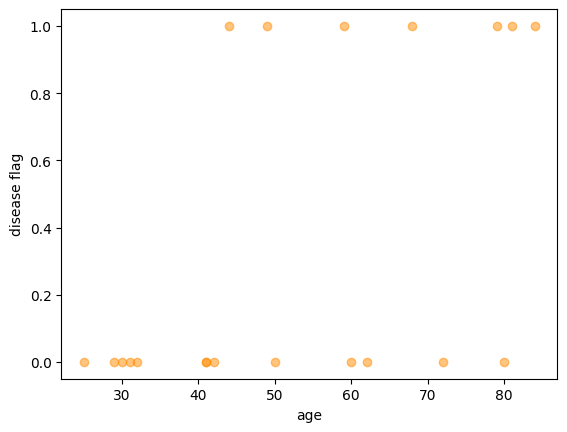

In [332]:
plt.plot(df['age'],df['disease'], 'o', color='darkorange', lw=0.2, alpha=0.5)
plt.xlabel('age')
plt.ylabel('disease flag')
plt.show()

In [333]:
# Variable explicative
X = df.drop(['disease'],axis=1)

# Variable cible
y = df['disease']

model = LogisticRegression()
model.fit(X, y)

# b0, b1
model.intercept_, model.coef_

(array([-4.36803094]), array([[0.06688661]]))

In [334]:
# Tableau de [P(sain), P(malade)]
# On choisit la 2nd colonne pour expliquer mais c'est le complément de la 1ère
y_pred = model.predict_proba(X)[:,1]
y_pred

array([0.06321775, 0.08103854, 0.08616132, 0.09157566, 0.09729401,
       0.16442301, 0.16442301, 0.17381984, 0.19387577, 0.25150772,
       0.26430719, 0.39610497, 0.41221055, 0.44495863, 0.54494295,
       0.61011716, 0.71422862, 0.72768278, 0.74073345, 0.77737671])

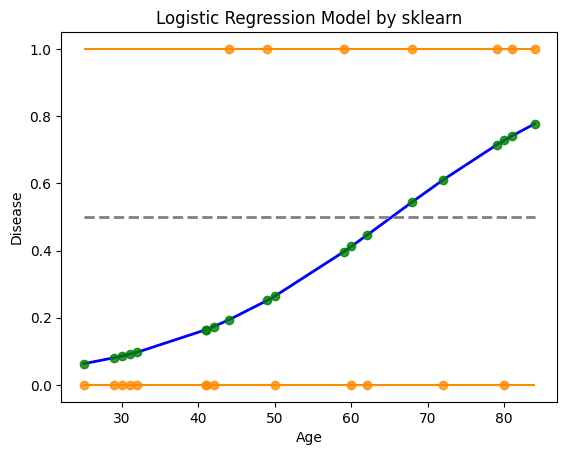

In [335]:
# Proba sous forme continue
plt.plot(X, y_pred, lw=2, color='blue')

# Probas sous forme de points
plt.plot(X, y_pred, 'o', color='green', alpha=0.8)

# Si malade ou non
plt.plot(X, y, 'o', color='darkorange', lw=2, alpha=0.8)

plt.hlines(1.0, min(X.values), max(X.values), color='darkorange', linestyle='-')
plt.hlines(0.5,min(X.values),max(X.values), color='grey', lw=2, linestyle='--')
plt.hlines(0.0, min(X.values), max(X.values), color='darkorange', linestyle='-')

plt.title('Logistic Regression Model by sklearn')
plt.xlabel('Age')
plt.ylabel('Disease')
plt.show()

On vérifie la courbe en recalculant les probas à la main

C:\Users\Christophe\AppData\Local\Temp\ipykernel_10368\2561226090.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.exp(g(x['age']))/(1+math.exp(g(x['age'])))


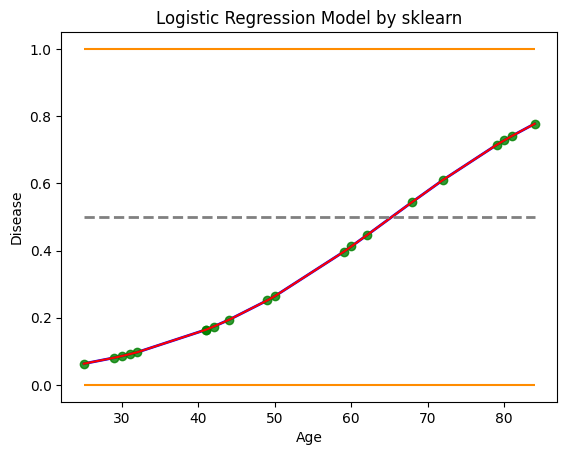

In [336]:
def g(x):
    b0 = model.intercept_
    b1 = model.coef_[0][0]
    return b0+b1*x

def pi(x):
    return math.exp(g(x['age']))/(1+math.exp(g(x['age'])))

df['analytic'] = df.apply(pi,axis=1)

plt.plot(X, y_pred, lw=2, color='blue')
plt.plot(X, y_pred, 'o', color='green', alpha=0.8)
plt.plot(X, df['analytic'], color='red')

plt.hlines(0.5,min(X.values),max(X.values), color='grey', lw=2, linestyle='--')
plt.hlines(0.0, min(X.values), max(X.values), color='darkorange', linestyle='-')
plt.hlines(1.0, min(X.values), max(X.values), color='darkorange', linestyle='-')

plt.title('Logistic Regression Model by sklearn')
plt.xlabel('Age')
plt.ylabel('Disease')
plt.show()

# E3

En repartant de la définition de la courbe logistique, montrer que les valeurs de paramètres obtenues dans l'exercice 2 correspondent bien au modèle de probabilité le plus probable compatible avec les données.

On réutilise le model.fit() de l'exercice 2 car c'est ce modèle qu'on veut tester.

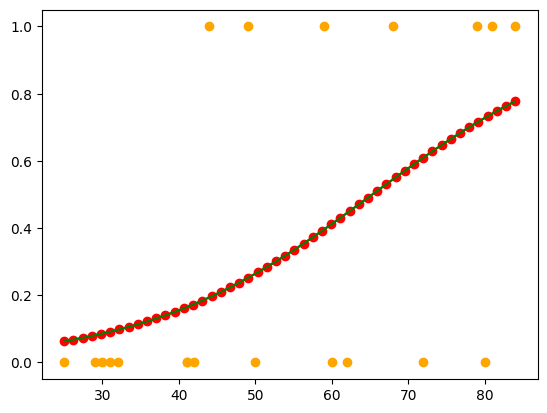

In [337]:
# On crée un dataframe alertnatif avec un X complet (celui du dataset a quelques trous au niveau des ages)
model_df = pd.DataFrame()

model_df['age'] = np.linspace(df['age'].min(),df['age'].max())
model.predict(model_df[['age']])
model_df['proba'] = model.predict_proba(model_df[['age']])[:,1]

beta_1 = model.coef_[0][0]
beta_0 = model.intercept_[0]

def g(x):
    return beta_0 + beta_1*x

def pi(x):
    return math.exp(g(x))/(1+math.exp(g(x)))

model_df['calculated_proba'] = model_df['age'].apply(lambda x:pi(x))

plt.plot(df['age'],df['disease'],'o',color='orange')
plt.plot(model_df['age'],model_df['proba'],'o-', color='red')
plt.plot(model_df['age'],model_df['calculated_proba'],'-',color='green')
plt.show()

In [ ]:
def g(x, beta_0, beta_1):
    return beta_0 + beta_1*x

def pi(x, beta_0, beta_1):
    return math.exp(g(x, beta_0, beta_1))/(1+math.exp(g(x, beta_0, beta_1)))

def likelihood(X, y, beta_0, beta_1):
    prod = 1.0
    for ix in range(X.shape[0]):
        # X.iloc[ix, 0] extrait la valeur scalaire de la première colonne ('age')
        x_val = X.iloc[ix, 0] 
        proba = pi(x_val, beta_0, beta_1)

        # Si il est malade (==1) alors le score gagne la proba, s'il est sain (==0) alors on enlève la proba inverse
        if y.iloc[ix] == 0:
            fact = 1 - proba
        else:
            fact = proba
            
        prod = fact * prod
    return prod

likelihood(X, y, beta_0, beta_1)

4.1049518962884825e-05

ça c'est le maximum de vraisemblance... si on dévie légèrement de ce point, cela devrait diminuer dans toutes les directions de l'espace (beta_0, beta_1).  
Voyons cela :

In [339]:
eps = 0.5

likelihood(X, y, beta_0, (1-eps)*beta_1), likelihood(X, y, (1+eps)*beta_0, beta_1), likelihood(X, y, (1-eps)*beta_0, beta_1)

(5.18448502034584e-08, 5.616981715139963e-08, 9.299057375338903e-09)

Cela semble bien le cas.  

Systématisons par une coupe selon beta_0 en gardant beta_1 fixe :  

In [340]:
beta_list = []
likelihood_list = []

for beta in np.linspace((1-eps)*beta_0,(1+eps)*beta_0):
    beta_list.append(beta)
    likelihood_list.append(likelihood(X, y, beta, beta_1))

df = pd.DataFrame()

df['beta_0'] = beta_list
df['likelihood'] = likelihood_list

df.head()

,beta_0,likelihood
0,-2.184015,9.299057e-09
1,-2.273159,1.813269e-08
2,-2.362302,3.446541e-08
3,-2.451446,6.382217e-08
4,-2.540589,1.150840e-07


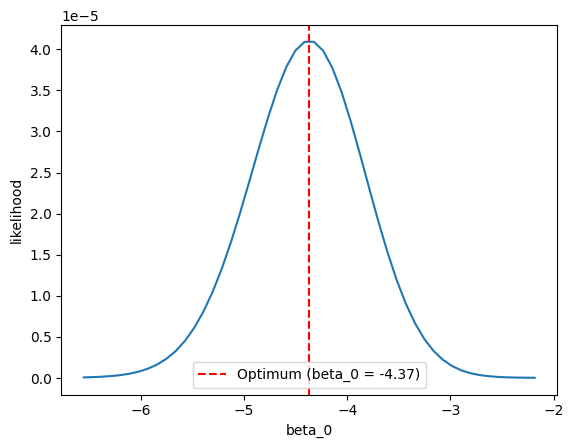

In [341]:
plt.plot(df['beta_0'], df['likelihood'])
plt.xlabel('beta_0')
plt.ylabel('likelihood')
plt.axvline(x=model.intercept_[0], color='red', linestyle='--', label=f'Optimum (beta_0 = {model.intercept_[0]:.2f})')
plt.legend()
plt.show()

De même, dans l'autre direction : gardons beta_0 à sa valeur optimale et varions beta_1. On obtient :

In [342]:
beta_list = []
likelihood_list = []

for beta in np.linspace((1-eps)*beta_1,(1+eps)*beta_1):
    beta_list.append(beta)
    likelihood_list.append(likelihood(X, y, beta_0, beta))

df = pd.DataFrame()

df['beta_1'] = beta_list
df['likelihood'] = likelihood_list

df.head()

,beta_1,likelihood
0,0.033443,5.184485e-08
1,0.034808,8.432519e-08
2,0.036173,1.354723e-07
3,0.037538,2.147893e-07
4,0.038903,3.357858e-07


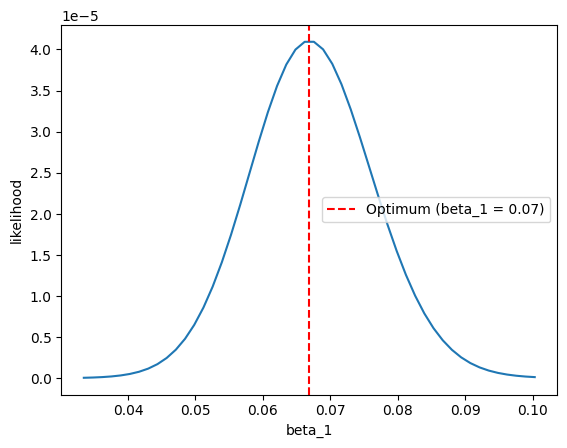

In [343]:
plt.plot(df['beta_1'], df['likelihood'])
plt.xlabel('beta_1')
plt.ylabel('likelihood')
plt.axvline(x=model.coef_[0][0], color='red', linestyle='--', label=f'Optimum (beta_1 = {model.coef_[0][0]:.2f})')
plt.legend()
plt.show()

Nous pouvons même explorer les deux dimensions ensemble. Voici :

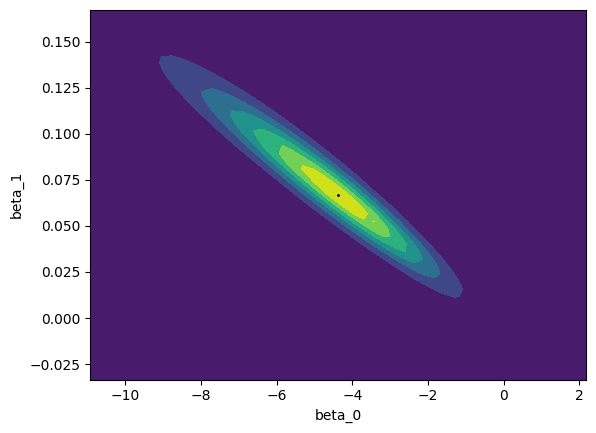

(np.float64(-4.368030937981224), np.float64(0.0668866064086253))

In [344]:
eps = 1.5
n_grid = 50

x_grid = np.linspace((1.+eps)*beta_0, (1.-eps)*beta_0, n_grid)
y_grid = np.linspace((1.-eps)*beta_1, (1.+eps)*beta_1, n_grid)
xx, yy = np.meshgrid(x_grid, y_grid)
zz = np.zeros((y_grid.size, x_grid.size))
for i in range(x_grid.size):
    for j in range(y_grid.size):
        zz[j,i] = likelihood(X, y, xx[j,i], yy[j,i])

plt.contourf(x_grid, y_grid, zz)
plt.xlabel('beta_0')
plt.ylabel('beta_1')
plt.scatter(beta_0, beta_1, color='black', s=1)
plt.show()

model.intercept_[0], model.coef_[0][0]